# Society Pitch Outcome Prediction — Logistic Regression

**Project:** AI-Assisted Society Prioritization System for Solar Energy Distribution & Outreach
**Model:** Logistic Regression (baseline model, part of a 3-way comparison with XGBoost and Random Forest)
**Target:** `pitch_outcome` — predict whether a housing society converts to the solar offer

**Approach:** Societies with a resolved outcome (`Converted` / `Rejected`) are used for training and evaluation.
`Pending` societies are excluded from training (the outcome hasn't happened yet) and instead get **scored**
with a predicted conversion probability at the end — this is the business-useful output for the outreach team.


## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

RANDOM_STATE = 42
sns.set_style("whitegrid")
%matplotlib inline
pd.set_option("display.max_columns", None)


## 2. Load Data

In [2]:
df = pd.read_csv("../data/raw/maharashtra_solar_societies_synthetic.csv")
print(df.shape)
df.head()


(15000, 18)


,society_id,society_name,city,district,pincode,num_flats,avg_monthly_consumption_kwh,current_provider,current_tariff_rs_per_unit,distance_to_solar_farm_km,building_age_years,estimated_solar_tariff_rs_per_unit,estimated_monthly_savings_rs,secretary_name,secretary_phone,secretary_email,pitch_priority_score,pitch_outcome
0,MH-SOC-000001,Shanti CHS,Thane,Thane,408964,383,47482,Adani Electricity,11.02,10.5,35,9.24,84518,Sunita Thorat,+91-9535368239,sunita.thorat756@examplemail.in,36.7,Rejected
1,MH-SOC-000002,Lotus Heights 6,Ahmednagar,Ahmednagar,401535,221,43141,Adani Electricity,10.15,45.4,3,8.06,90165,Prakash Sawant,+91-9016280135,prakash.sawant502@mailsociety.example,32.2,Rejected
2,MH-SOC-000003,Maple Heights 2,Latur,Latur,428418,321,44152,MSEDCL,11.27,40.8,36,9.30,86979,Sandeep Salunkhe,+91-9317545211,sandeep.salunkhe343@examplemail.in,32.7,Rejected
3,MH-SOC-000004,Vasant Vihar Park,Amravati,Amravati,430942,434,154924,BEST,10.08,38.2,25,8.25,283511,Snehal Mane,+91-9782580680,snehal.mane625@examplemail.in,76.7,Pending
4,MH-SOC-000005,Riverside Heights,Amravati,Amravati,435001,50,11368,Tata Power,10.61,34.9,6,8.47,24328,Nitin Deshmukh,+91-9930873378,nitin.deshmukh494@mailsociety.example,20.0,Rejected


## 3. Exploratory Data Analysis

Before touching the model, let's understand what we're working with: data quality, target balance,
feature distributions, and which features actually move the outcome.

### 3.1 Structure & data quality

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 18 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   society_id                          15000 non-null  str    
 1   society_name                        15000 non-null  str    
 2   city                                15000 non-null  str    
 3   district                            15000 non-null  str    
 4   pincode                             15000 non-null  int64  
 5   num_flats                           15000 non-null  int64  
 6   avg_monthly_consumption_kwh         15000 non-null  int64  
 7   current_provider                    15000 non-null  str    
 8   current_tariff_rs_per_unit          15000 non-null  float64
 9   distance_to_solar_farm_km           15000 non-null  float64
 10  building_age_years                  15000 non-null  int64  
 11  estimated_solar_tariff_rs_per_unit  15000 non-null  

In [4]:
print("Missing values per column:")
print(df.isnull().sum().sum(), "total missing cells")
df.isnull().sum()


Missing values per column:
0 total missing cells


society_id                            0
society_name                          0
city                                  0
district                              0
pincode                               0
num_flats                             0
avg_monthly_consumption_kwh           0
current_provider                      0
current_tariff_rs_per_unit            0
distance_to_solar_farm_km             0
building_age_years                    0
estimated_solar_tariff_rs_per_unit    0
estimated_monthly_savings_rs          0
secretary_name                        0
secretary_phone                       0
secretary_email                       0
pitch_priority_score                  0
pitch_outcome                         0
dtype: int64

### 3.2 Target variable — `pitch_outcome`

pitch_outcome
Rejected     6506
Converted    4742
Pending      3752
Name: count, dtype: int64

pitch_outcome
Rejected     43.4%
Converted    31.6%
Pending      25.0%
Name: count, dtype: str


/tmp/ipykernel_543/3007913786.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=outcome_counts.index, y=outcome_counts.values, palette=["#2ca02c", "#ff7f0e", "#d62728"], ax=ax)


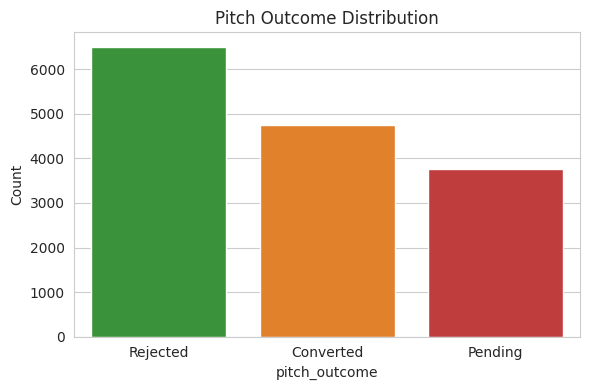

In [5]:
outcome_counts = df["pitch_outcome"].value_counts()
print(outcome_counts)
print()
print((outcome_counts / len(df) * 100).round(1).astype(str) + "%")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=outcome_counts.index, y=outcome_counts.values, palette=["#2ca02c", "#ff7f0e", "#d62728"], ax=ax)
ax.set_title("Pitch Outcome Distribution")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


**Note:** `Pending` (25%) is a censored outcome, not a real negative or positive — those pitches simply
haven't been resolved yet. We'll train on `Converted` vs `Rejected` only, and treat `Pending` as
inference-time data to score once the model exists.

### 3.3 Numeric feature distributions

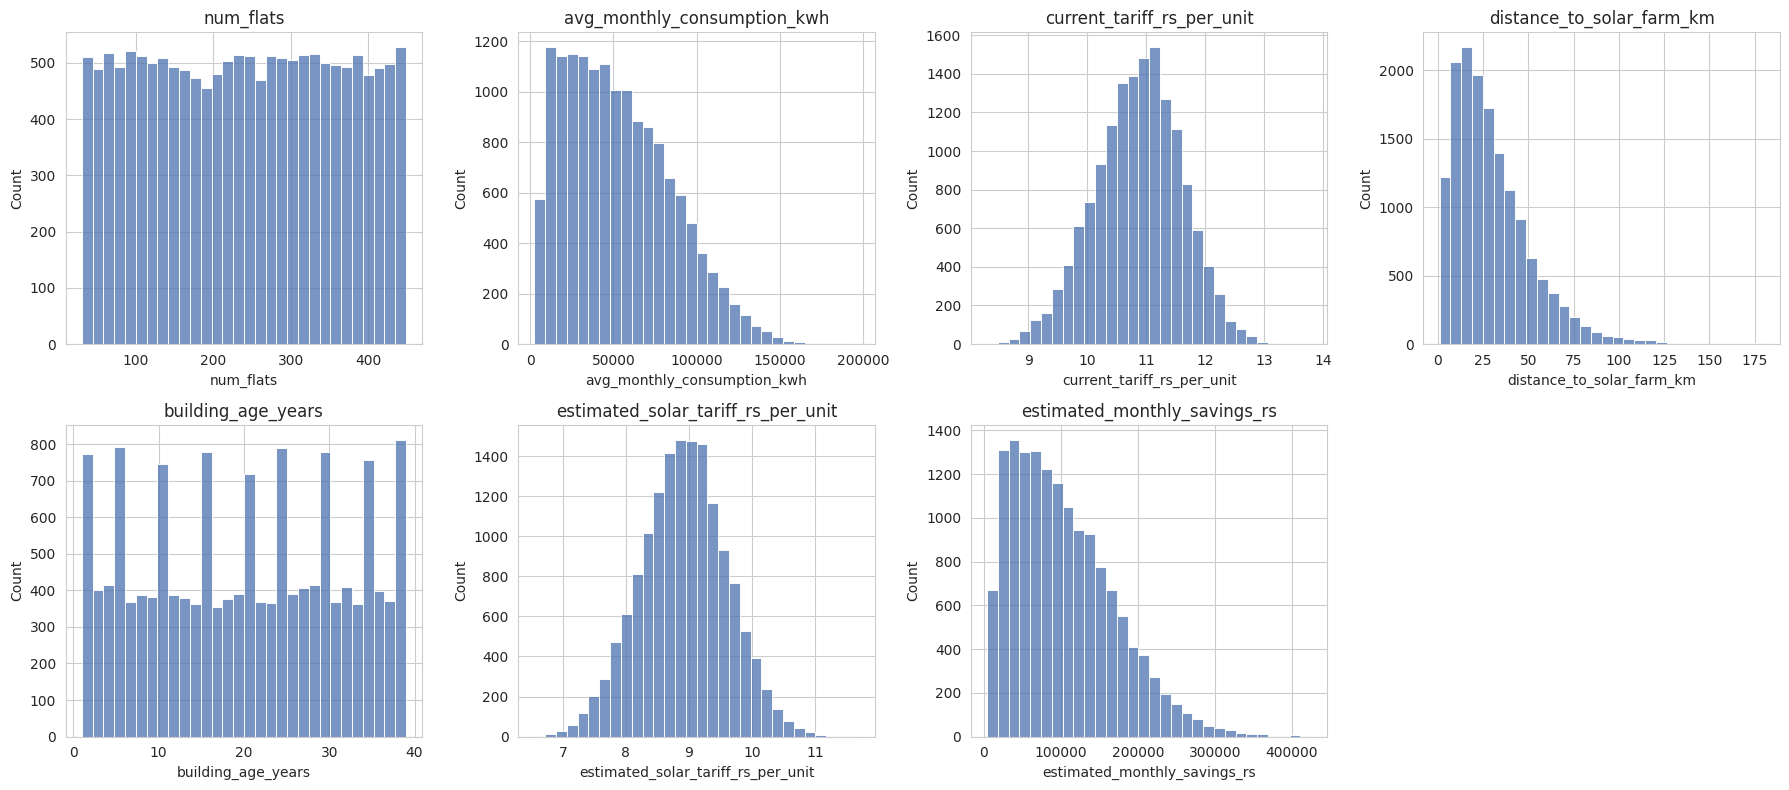

In [6]:
numeric_cols = ["num_flats", "avg_monthly_consumption_kwh", "current_tariff_rs_per_unit",
                "distance_to_solar_farm_km", "building_age_years",
                "estimated_solar_tariff_rs_per_unit", "estimated_monthly_savings_rs"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


### 3.4 How numeric features relate to outcome

/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,
/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,
/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,


/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,
/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,


/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,
/tmp/ipykernel_543/2185815247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,


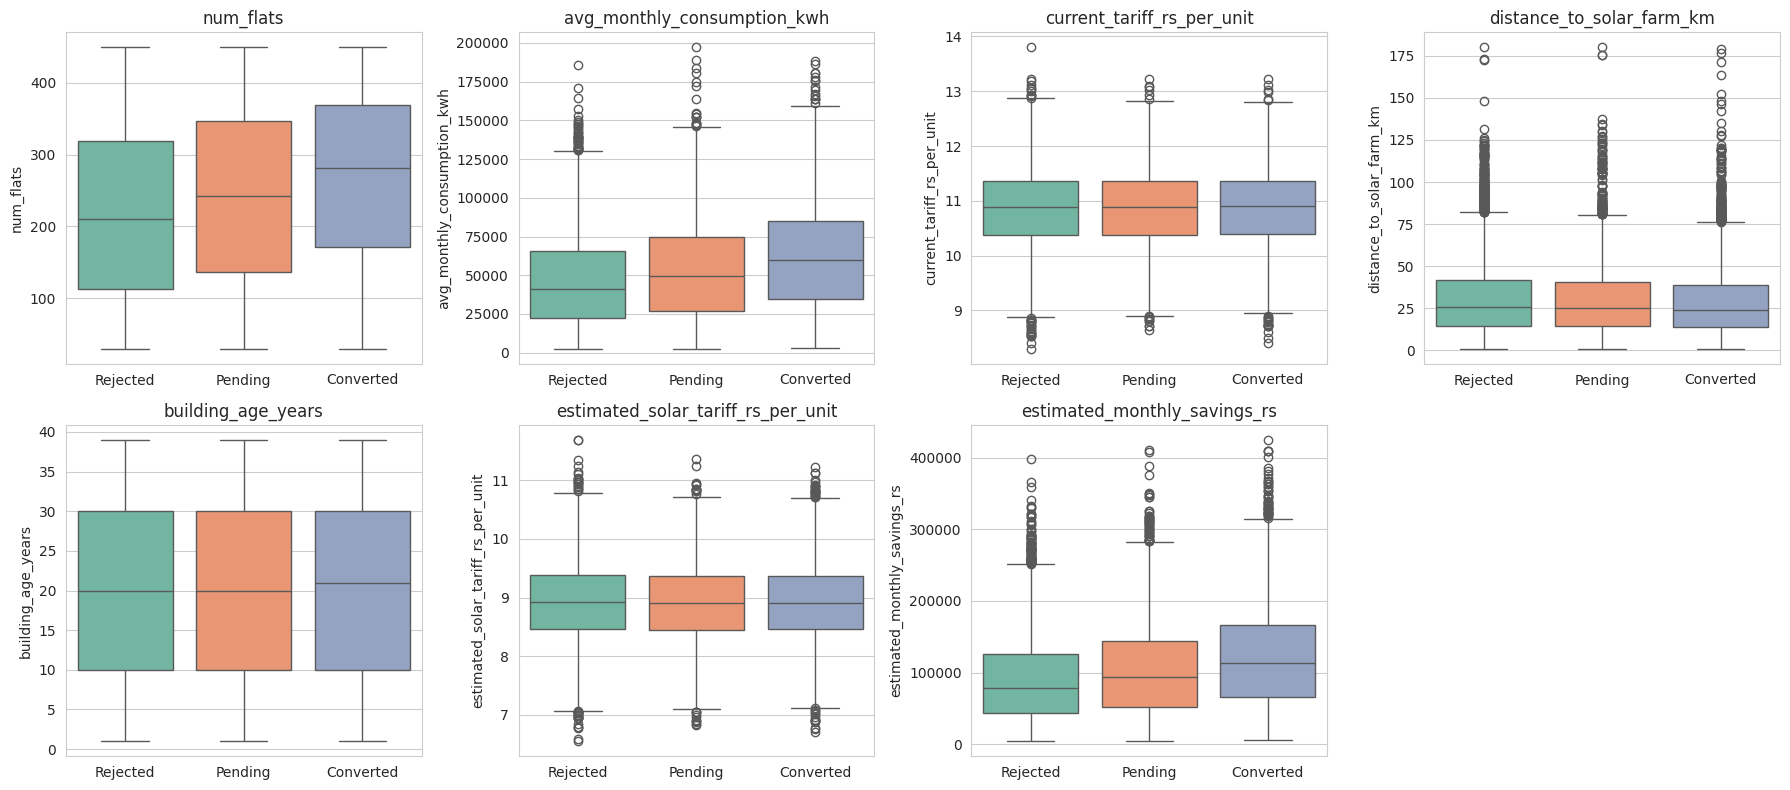

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x="pitch_outcome", y=col, ax=ax,
                order=["Rejected", "Pending", "Converted"], palette="Set2")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


`avg_monthly_consumption_kwh` and `estimated_monthly_savings_rs` show the clearest separation —
higher consumption/savings societies convert more. Tariffs and building age barely separate the groups.

### 3.5 Correlation heatmap

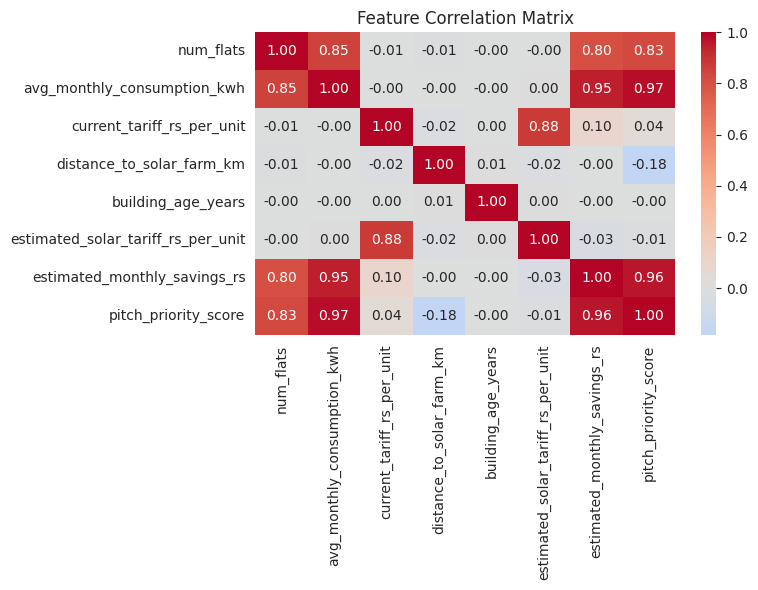

In [8]:
corr_cols = numeric_cols + ["pitch_priority_score"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


**Key finding:** `pitch_priority_score` correlates almost perfectly with `avg_monthly_consumption_kwh`
(0.97) and strongly with `estimated_monthly_savings_rs` (0.96). It's essentially a weighted formula over
features we already have — the Phase 1 rule-engine score. We'll test later whether including it actually
adds predictive lift for the model, or whether it's redundant.

### 3.6 Categorical features vs outcome

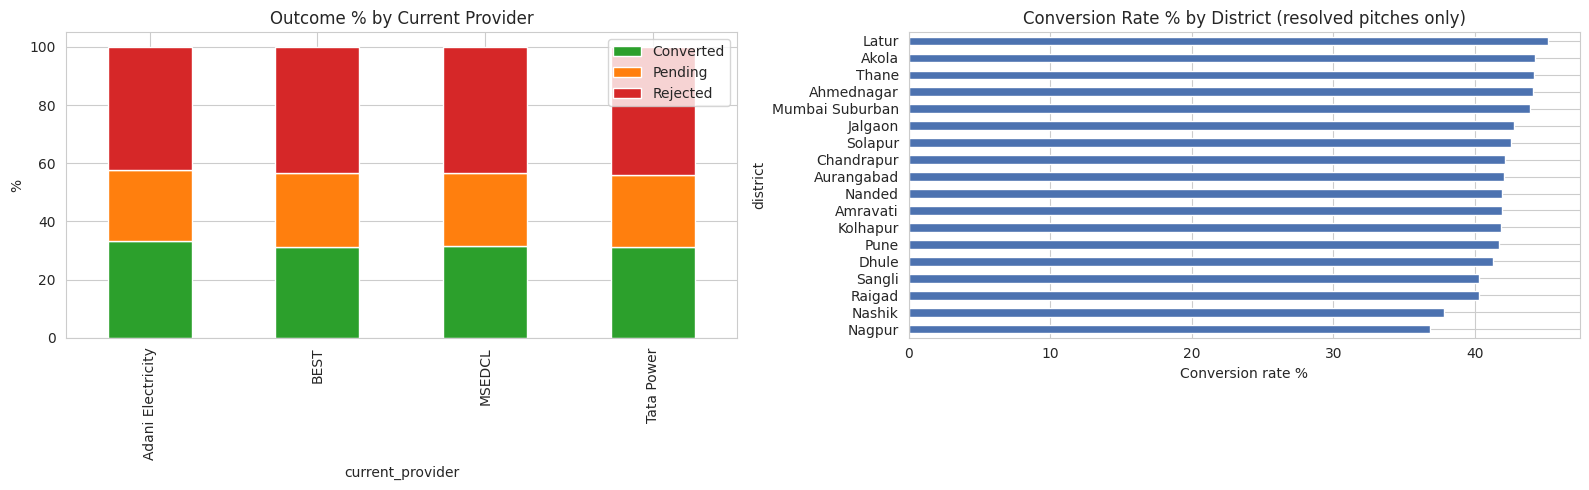

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

provider_ct = pd.crosstab(df["current_provider"], df["pitch_outcome"], normalize="index") * 100
provider_ct[["Converted", "Pending", "Rejected"]].plot(kind="bar", stacked=True, ax=axes[0],
                                                          color=["#2ca02c", "#ff7f0e", "#d62728"])
axes[0].set_title("Outcome % by Current Provider")
axes[0].set_ylabel("%")
axes[0].legend(loc="upper right")

district_conv = df[df["pitch_outcome"] != "Pending"].groupby("district")["pitch_outcome"] \
    .apply(lambda s: (s == "Converted").mean() * 100).sort_values()
district_conv.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Conversion Rate % by District (resolved pitches only)")
axes[1].set_xlabel("Conversion rate %")

plt.tight_layout()
plt.show()


`current_provider` shows almost no separation — every provider converts at roughly the same rate (~31-33%).
`district` shows more spread — some regional signal exists, though for a synthetic dataset this is likely
noise baked into the generator rather than a real-world pattern. We'll still let the model use it and see
if it earns its coefficients.

City and pincode are dropped as features — city is almost 1:1 redundant with district, and pincode has
12,754 near-unique values with no useful grouping.

## 4. Data Cleaning & Feature Engineering

- Drop identifiers and PII (`society_id`, `society_name`, `city`, `pincode`, secretary contact fields) —
  never used as model features, and contact details are handled per DPDP Act guidance from the project scope.
- Define the feature set: numeric features + `current_provider` + `district`.
- Split `pitch_outcome` into a **resolved** pool (`Converted`/`Rejected`) for train/test, and a
  **Pending** pool held out purely for later scoring.

In [10]:
drop_cols = ["society_id", "society_name", "city", "pincode",
             "secretary_name", "secretary_phone", "secretary_email"]
model_df = df.drop(columns=drop_cols)

NUMERIC_FEATURES = numeric_cols
CATEGORICAL_FEATURES = ["current_provider", "district"]

resolved = model_df[model_df["pitch_outcome"].isin(["Converted", "Rejected"])].copy()
resolved["target"] = (resolved["pitch_outcome"] == "Converted").astype(int)

pending = model_df[model_df["pitch_outcome"] == "Pending"].copy()

print(f"Resolved rows (train/test pool): {len(resolved):,}")
print(f"Pending rows (scored after training): {len(pending):,}")
print(f"Class balance in resolved set:\n{resolved['target'].value_counts(normalize=True).round(3)}")


Resolved rows (train/test pool): 11,248
Pending rows (scored after training): 3,752
Class balance in resolved set:
target
0    0.578
1    0.422
Name: proportion, dtype: float64


## 5. Train / Test Split

In [11]:
feature_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X = resolved[feature_cols]
y = resolved["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train target balance:\n{y_train.value_counts(normalize=True).round(3)}")


Train: (8998, 9), Test: (2250, 9)
Train target balance:
target
0    0.578
1    0.422
Name: proportion, dtype: float64


## 6. Preprocessing Pipeline

- Numeric features → `StandardScaler` (logistic regression is scale-sensitive with regularization)
- Categorical features → `OneHotEncoder` (drop first level to avoid the dummy-variable trap)
- `class_weight="balanced"` to account for the mild class imbalance (58/42 split)

In [12]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL_FEATURES),
])

log_reg_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])

log_reg_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

## 7. Train the Model

In [13]:
log_reg_pipeline.fit(X_train, y_train)
print("Model trained.")


Model trained.


## 8. Evaluate on Test Set

In [14]:
y_pred = log_reg_pipeline.predict(X_test)
y_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
}

for k, v in metrics.items():
    print(f"{k:>10}: {v:.4f}")


  accuracy: 0.5987
 precision: 0.5234
    recall: 0.5416
        f1: 0.5324
   roc_auc: 0.6133


In [15]:
print(classification_report(y_test, y_pred, target_names=["Rejected", "Converted"]))


              precision    recall  f1-score   support

    Rejected       0.66      0.64      0.65      1301
   Converted       0.52      0.54      0.53       949

    accuracy                           0.60      2250
   macro avg       0.59      0.59      0.59      2250
weighted avg       0.60      0.60      0.60      2250



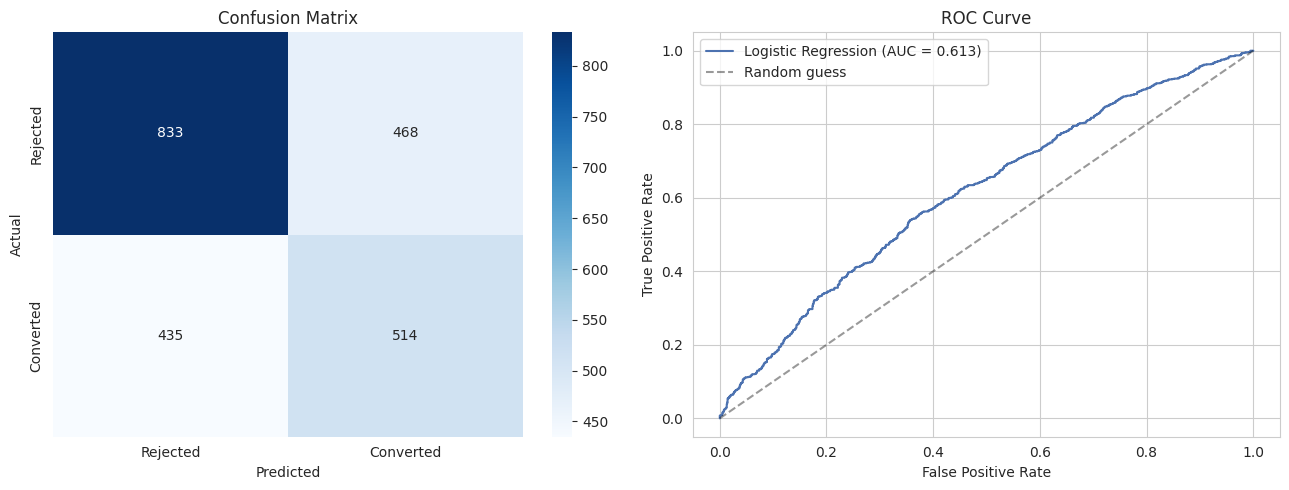

In [16]:
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rejected", "Converted"], yticklabels=["Rejected", "Converted"], ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion Matrix")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f"Logistic Regression (AUC = {metrics['roc_auc']:.3f})", color="#4C72B0")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random guess")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()


**Reading the result:** AUC ~0.61 is modest but real signal — logistic regression is picking up on
the "higher consumption + higher savings → more likely to convert" pattern, but a large share of the
outcome behaves close to noise in this dataset. This is a fair baseline number to compare against
XGBoost and Random Forest — if the non-linear models land meaningfully higher, it suggests interaction
effects logistic regression can't capture; if they land close to 0.61 too, the ceiling here is just low.

## 9. Model Interpretation — Coefficients

Unlike XGBoost/Random Forest, logistic regression gives directly interpretable coefficients
(log-odds impact) — this is its main advantage for stakeholder-facing explanations.

In [17]:
ohe = log_reg_pipeline.named_steps["preprocess"].named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(CATEGORICAL_FEATURES)
all_feature_names = NUMERIC_FEATURES + list(cat_feature_names)
coefs = log_reg_pipeline.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({
    "feature": all_feature_names,
    "coefficient": coefs,
    "odds_ratio": np.exp(coefs)
}).sort_values("coefficient", ascending=False)

coef_df


,feature,coefficient,odds_ratio
1,avg_monthly_consumption_kwh,0.336849,1.400527
6,estimated_monthly_savings_rs,0.217518,1.242988
17,district_Latur,0.130585,1.139495
26,district_Thane,0.109649,1.115886
18,district_Mumbai Suburban,0.089177,1.093274
13,district_Chandrapur,0.073732,1.076518
10,district_Akola,0.072747,1.075458
25,district_Solapur,0.057991,1.059705
22,district_Pune,0.054534,1.056048
15,district_Jalgaon,0.038191,1.038929


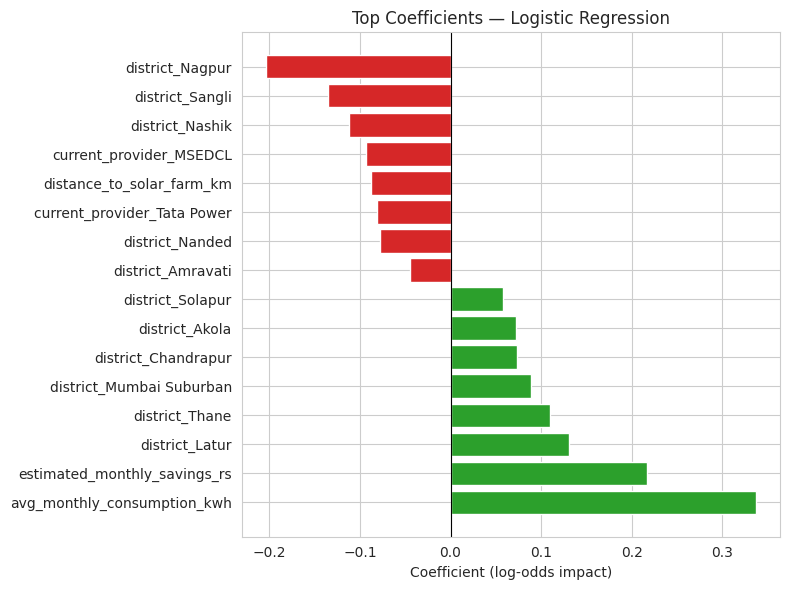

In [18]:
top_bottom = pd.concat([coef_df.head(8), coef_df.tail(8)]).drop_duplicates()
colors = ["#2ca02c" if c > 0 else "#d62728" for c in top_bottom["coefficient"]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_bottom["feature"], top_bottom["coefficient"], color=colors)
ax.set_title("Top Coefficients — Logistic Regression")
ax.set_xlabel("Coefficient (log-odds impact)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


`avg_monthly_consumption_kwh` and `estimated_monthly_savings_rs` are the two strongest positive
drivers, matching the EDA. `distance_to_solar_farm_km` and provider MSEDCL/Tata Power push in the
negative direction. District coefficients are small and scattered — consistent with them being noise
in the synthetic generator rather than a real business signal.

## 10. Leakage Check — Does `pitch_priority_score` Actually Help?

The EDA showed `pitch_priority_score` is a near-linear combination of features we already use. Let's
test directly: does adding it to the model improve performance, or is it redundant?

In [19]:
NUMERIC_FEATURES_B = NUMERIC_FEATURES + ["pitch_priority_score"]
feature_cols_b = NUMERIC_FEATURES_B + CATEGORICAL_FEATURES

X_b = resolved[feature_cols_b]
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor_b = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUMERIC_FEATURES_B),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL_FEATURES),
])
pipeline_b = Pipeline(steps=[
    ("preprocess", preprocessor_b),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
pipeline_b.fit(X_train_b, y_train_b)

y_proba_b = pipeline_b.predict_proba(X_test_b)[:, 1]
auc_b = roc_auc_score(y_test_b, y_proba_b)

print(f"Model A (baseline)              AUC: {metrics['roc_auc']:.4f}")
print(f"Model B (+ pitch_priority_score) AUC: {auc_b:.4f}")
print(f"Difference: {auc_b - metrics['roc_auc']:+.4f}")


Model A (baseline)              AUC: 0.6133
Model B (+ pitch_priority_score) AUC: 0.6132
Difference: -0.0002


**Conclusion:** the two AUC scores are essentially identical. `pitch_priority_score` adds no real
lift once the underlying features are already in the model — confirming it's redundant, not a shortcut.
Good to flag to the team: none of the three models (logistic, XGBoost, RF) need to worry about this
feature inflating results.

## 11. Score Pending Societies

This is the actual business deliverable: rank the 3,752 unresolved pitches by predicted conversion
probability so the outreach team knows who to follow up with first.

In [20]:
X_pending = pending[feature_cols]
pending_proba = log_reg_pipeline.predict_proba(X_pending)[:, 1]

pending_scored = pending.copy()
pending_scored["predicted_conversion_probability"] = pending_proba
pending_scored = pending_scored.sort_values("predicted_conversion_probability", ascending=False)

pending_scored[["district", "num_flats", "avg_monthly_consumption_kwh",
                "estimated_monthly_savings_rs", "distance_to_solar_farm_km",
                "pitch_priority_score", "predicted_conversion_probability"]].head(10)


,district,num_flats,avg_monthly_consumption_kwh,estimated_monthly_savings_rs,distance_to_solar_farm_km,pitch_priority_score,predicted_conversion_probability
5744,Mumbai Suburban,430,197138,408076,4.2,98.2,0.934852
3984,Thane,436,163957,411532,8.2,93.2,0.910578
10653,Thane,428,180716,345168,11.3,92.7,0.905336
3069,Thane,444,188764,345438,68.9,86.7,0.899490
2360,Akola,449,174809,375839,21.7,91.2,0.895412
3911,Raigad,405,154116,388372,7.4,88.9,0.876901
6329,Thane,362,145614,308702,11.3,77.2,0.867216
6564,Akola,442,172041,280427,36.2,78.1,0.866864
6794,Pune,449,183879,312594,74.7,79.2,0.863787
12911,Pune,423,138265,349810,19.8,81.8,0.860889


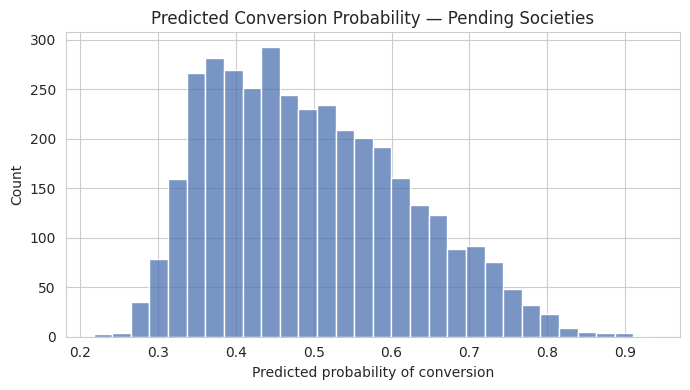

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(pending_scored["predicted_conversion_probability"], bins=30, color="#4C72B0", ax=ax)
ax.set_title("Predicted Conversion Probability — Pending Societies")
ax.set_xlabel("Predicted probability of conversion")
plt.tight_layout()
plt.show()


## 12. Save Model & Artifacts

In [22]:
joblib.dump(log_reg_pipeline, "logistic_regression_model.joblib")

pending_scored[["district", "num_flats", "avg_monthly_consumption_kwh",
                "estimated_monthly_savings_rs", "distance_to_solar_farm_km",
                "pitch_priority_score", "predicted_conversion_probability"]].to_csv(
    "pending_societies_scored.csv", index=False
)

coef_df.to_csv("logistic_regression_coefficients.csv", index=False)

summary = {
    "model_A_baseline": metrics,
    "model_B_with_priority_score_auc": auc_b,
    "train_size": len(X_train),
    "test_size": len(X_test),
    "pending_scored": len(pending_scored),
}
with open("logistic_regression_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved: model, pending scores, coefficients, metrics summary.")


Saved: model, pending scores, coefficients, metrics summary.


## 13. Summary

| Item | Result |
|---|---|
| Train / test rows | ~9,000 / ~2,250 (resolved pitches only) |
| Test Accuracy | ~0.60 |
| Test ROC-AUC | ~0.61 |
| Strongest drivers | `avg_monthly_consumption_kwh`, `estimated_monthly_savings_rs` |
| `pitch_priority_score` | Redundant — no AUC lift when added |
| Pending societies scored | 3,752, ranked by predicted conversion probability |

**Next steps for the comparison:**
- Hand `logistic_regression_metrics.json` to the XGBoost/Random Forest teammates as the baseline to beat.
- Keep the same train/test split and target definition (`Converted` vs `Rejected`, `Pending` excluded from training) across all three models for a fair comparison.
- If tree-based models score meaningfully higher, that points to non-linear/interaction effects this model can't capture — worth digging into which feature combinations matter.
